# XY EarlyAlert Drift Audit

## Environment Setup and Data Loading

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, roc_auc_score, recall_score,
    precision_score, confusion_matrix
)
from scipy.stats import ks_2samp, wasserstein_distance

RANDOM_STATE = 42
THRESHOLD = 0.30

data_dir = Path.cwd().parent / "data"
df23 = pd.read_csv(data_dir / "XY_fall2023_cohort.csv")
df25 = pd.read_csv(data_dir / "XY_fall2025_cohort.csv")

print("Fall 2023 shape:", df23.shape)
print("Fall 2025 shape:", df25.shape)
print("Missing values (2023):", int(df23.isna().sum().sum()))
print("Missing values (2025):", int(df25.isna().sum().sum()))

Fall 2023 shape: (4200, 16)
Fall 2025 shape: (3900, 16)
Missing values (2023): 0
Missing values (2025): 0


In [2]:
# print the dataset Sample
df23.head()

,student_id,intake_term,program,delivery_mode,age,international,first_generation,financial_aid,hs_average,credits_attempted,work_hours_week,commute_minutes,lms_logins_first4wks,assignments_submitted_pct,outstanding_balance,did_not_return
0,NB23-00001,Fall 2023,Skilled Trades,in_person,22,1,0,1,71.6,9,15,64,32,79,0,0
1,NB23-00002,Fall 2023,Health Sciences,in_person,21,0,0,0,65.4,15,13,17,32,76,560,0
2,NB23-00003,Fall 2023,Computer Programming,in_person,21,0,0,1,71.5,15,10,27,20,84,0,1
3,NB23-00004,Fall 2023,Business,in_person,18,0,0,0,76.0,18,4,10,37,100,0,0
4,NB23-00005,Fall 2023,Hospitality,in_person,35,0,0,0,78.3,15,19,37,16,77,0,0


## Baseline Model Development | Fall 2023
### Exploratory Data Analysis

#### Display the data types

In [3]:
# Print column datatypes using .dtypes
df23.dtypes

student_id                       str
intake_term                      str
program                          str
delivery_mode                    str
age                            int64
international                  int64
first_generation               int64
financial_aid                  int64
hs_average                   float64
credits_attempted              int64
work_hours_week                int64
commute_minutes                int64
lms_logins_first4wks           int64
assignments_submitted_pct      int64
outstanding_balance            int64
did_not_return                 int64
dtype: object

#### Find and count the missing data

In [4]:
df23.isna().sum()

student_id                   0
intake_term                  0
program                      0
delivery_mode                0
age                          0
international                0
first_generation             0
financial_aid                0
hs_average                   0
credits_attempted            0
work_hours_week              0
commute_minutes              0
lms_logins_first4wks         0
assignments_submitted_pct    0
outstanding_balance          0
did_not_return               0
dtype: int64

#### Display summary statistics for the numerical features

In [5]:
bin_cols = ["international", "first_generation", "financial_aid"]

num_cols =  [
    col for col in df23.select_dtypes(include="number").columns
    if col not in bin_cols and col != "did_not_return"
]

In [6]:
# Summarize numerical features
display(df23.describe().T)

print("Fall 2023 dropout rate:", round(float(df23["did_not_return"].mean()), 4))

,count,mean,std,min,25%,50%,75%,max
age,4200.0,21.570952,4.976220,17.0,19.0,20.0,21.0,51.0
international,4200.0,0.311667,0.463230,0.0,0.0,0.0,1.0,1.0
first_generation,4200.0,0.331429,0.470783,0.0,0.0,0.0,1.0,1.0
financial_aid,4200.0,0.483333,0.499782,0.0,0.0,0.0,1.0,1.0
hs_average,4200.0,76.100310,7.907150,55.0,70.7,75.9,81.4,99.0
credits_attempted,4200.0,14.207143,2.644436,9.0,12.0,15.0,15.0,18.0
work_hours_week,4200.0,13.362143,9.801048,0.0,6.0,11.0,18.0,45.0
commute_minutes,4200.0,27.802857,22.004117,0.0,12.0,24.0,39.0,185.0
lms_logins_first4wks,4200.0,28.757857,12.035143,4.0,20.0,27.0,35.0,103.0
assignments_submitted_pct,4200.0,77.372857,14.473503,8.0,68.0,78.0,88.0,100.0


Fall 2023 dropout rate: 0.2407


#### Binary features distribution

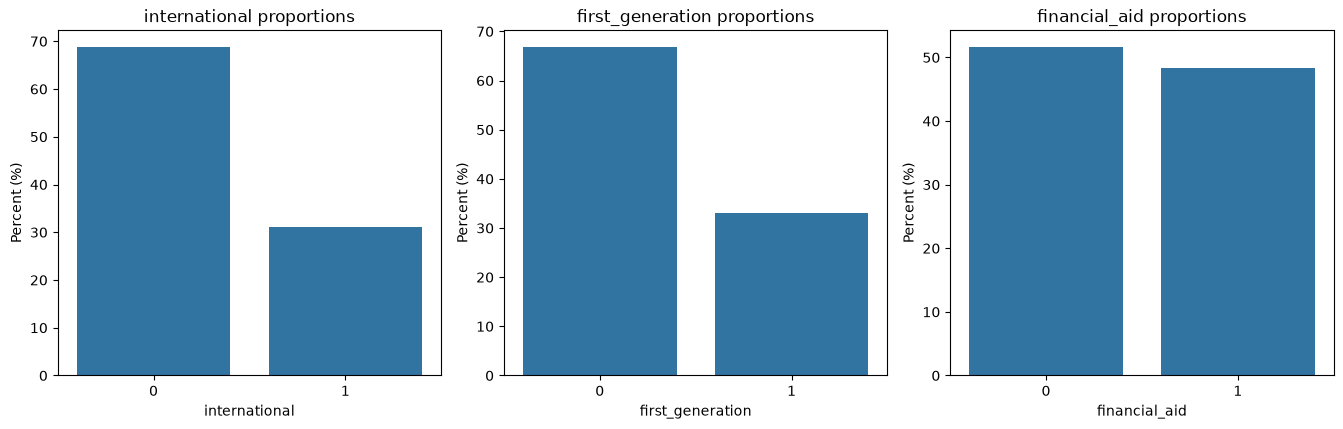

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for ax, col in zip(axes, bin_cols):
    proportions = df23[col].value_counts(normalize=True).sort_index() * 100
    sns.barplot(
        x=proportions.index.astype(str),
        y=proportions.values,
        ax=ax
    )
    ax.set(title=f"{col} proportions", xlabel=col, ylabel="Percent (%)")

for ax in axes[len(bin_cols):]:
    ax.set_visible(False)

fig.tight_layout()
plt.show()

#### Numerical features distribution

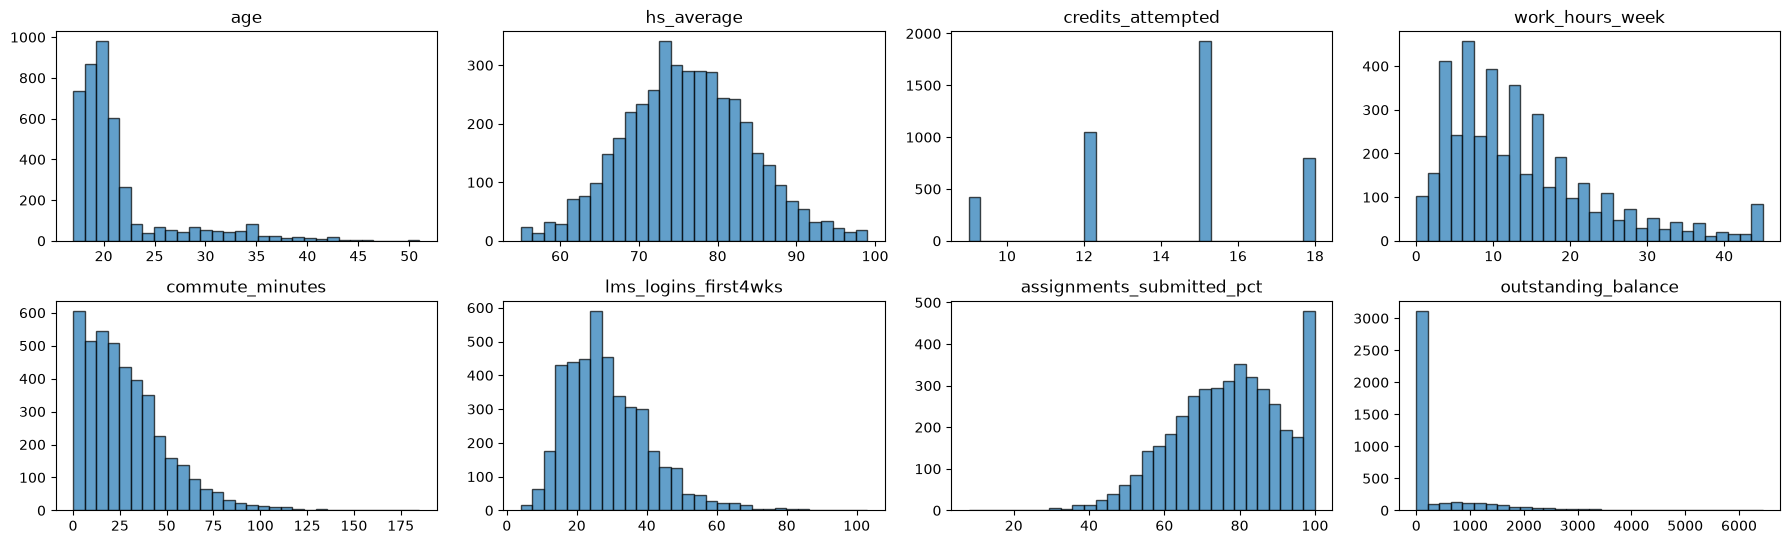

In [8]:
fig, axes = plt.subplots(3, 4, figsize=(18, 8))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    ax.hist(df23[col].dropna(), bins=30, edgecolor="black", alpha=0.7)
    ax.set_title(col)

for ax in axes[len(num_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

#### Calculating correlation

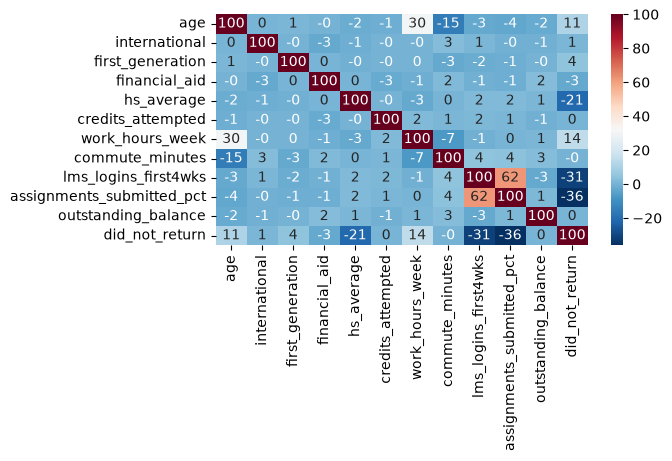

In [9]:
# Calculate correlations between numeric features
matrix = df23.corr(numeric_only=True)

# Make the figsize 8 x 6,so that the plot is a bit larger 
plt.figure(figsize=(6,3))

# Plot heatmap of annotated correlations
sns.heatmap(matrix * 100,
            cmap='RdBu_r',
            annot=True,
            fmt='.0f')

plt.show()

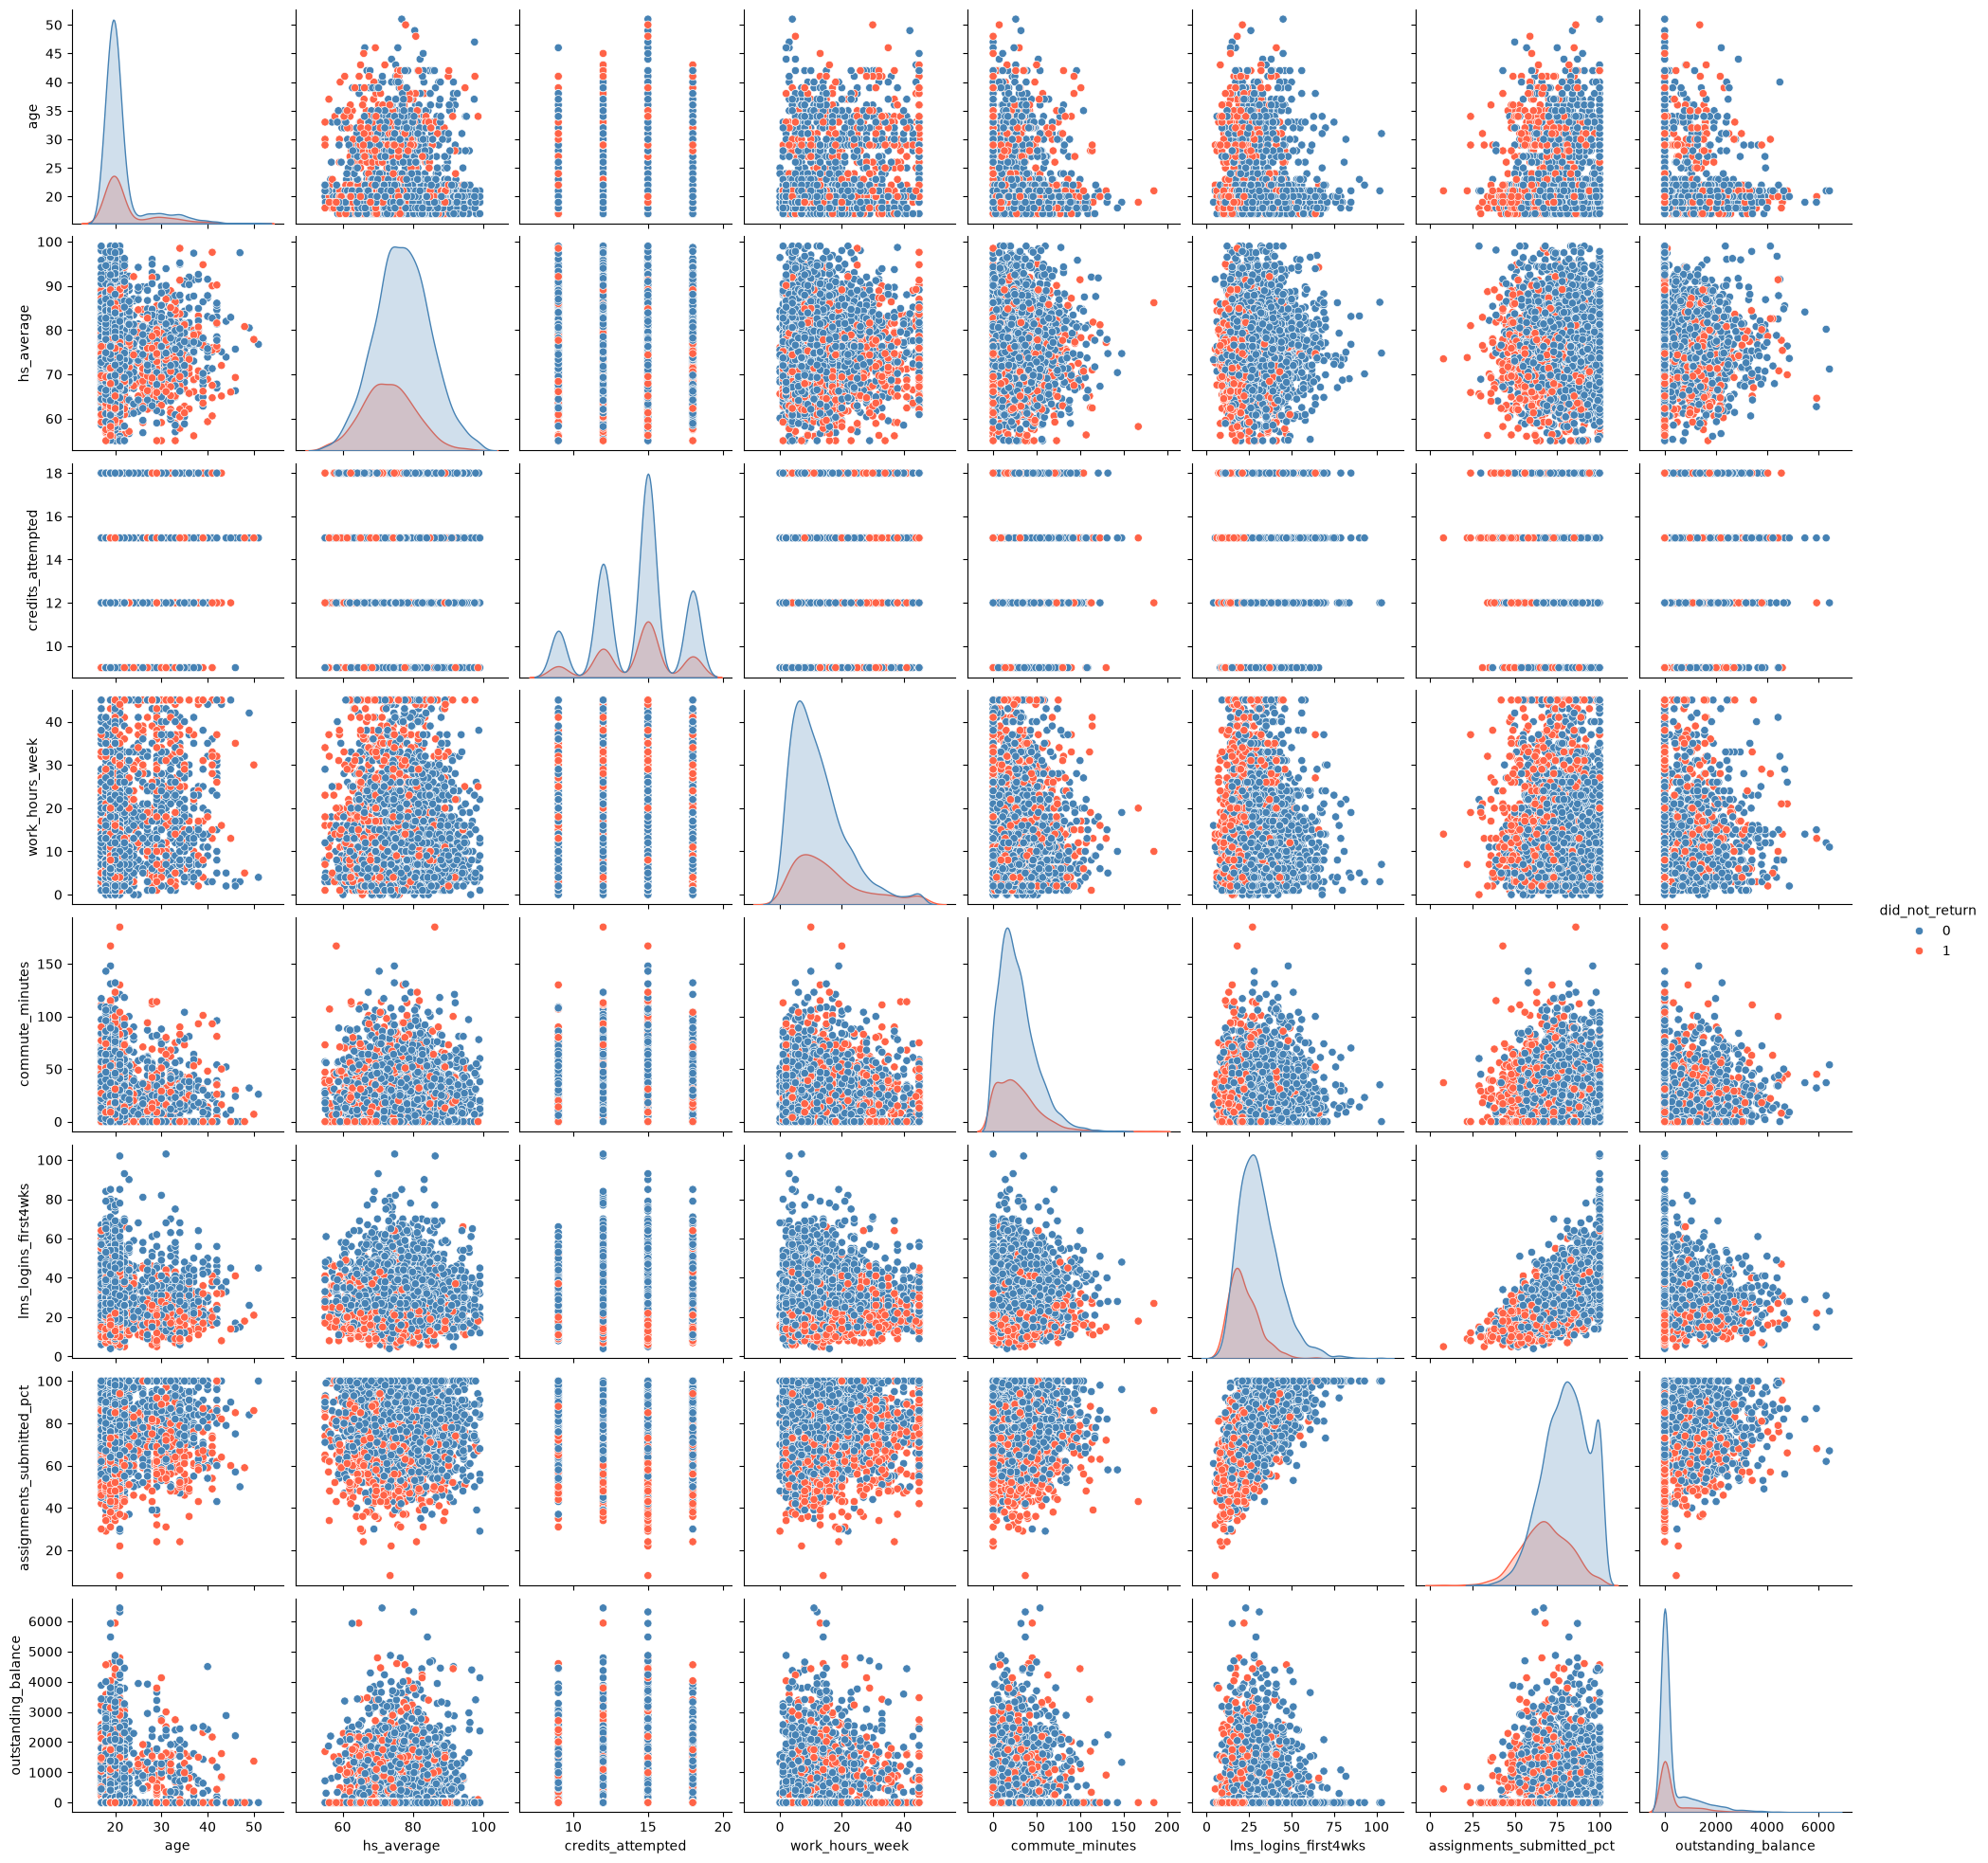

In [10]:
sns.pairplot(
    df23[num_cols + ["did_not_return"]],
    hue="did_not_return",
    palette={0: "steelblue", 1: "tomato"}
)
plt.show()

#### Look at the distributions of categorical features

In [11]:
# Summarize categorical features
df23.describe(include=['str']).T

,count,unique,top,freq
student_id,4200,4200,NB23-00001,1
intake_term,4200,1,Fall 2023,4200
program,4200,6,Skilled Trades,758
delivery_mode,4200,3,in_person,2975


Plot bar plots of each of the categorical features

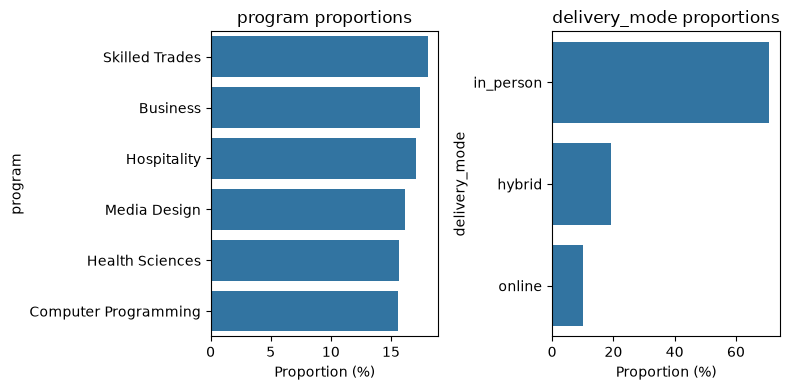

In [12]:
cat_cols = [
    feature
    for feature in df23.select_dtypes(
        include=["object", "string", "category"]
    ).columns
    if feature not in ["student_id", "intake_term"]
]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes = axes.flatten()

for ax, feature in zip(axes, cat_cols):
    proportions = df23[feature].value_counts(normalize=True) * 100
    sns.barplot(
        x=proportions.values,
        y=proportions.index.astype(str),
        ax=ax
    )
    ax.set(
        xlabel="Proportion (%)",
        ylabel=feature,
        title=f"{feature} proportions"
    )

for ax in axes[len(cat_cols):]:
    ax.set_visible(False)

fig.tight_layout()
plt.show()

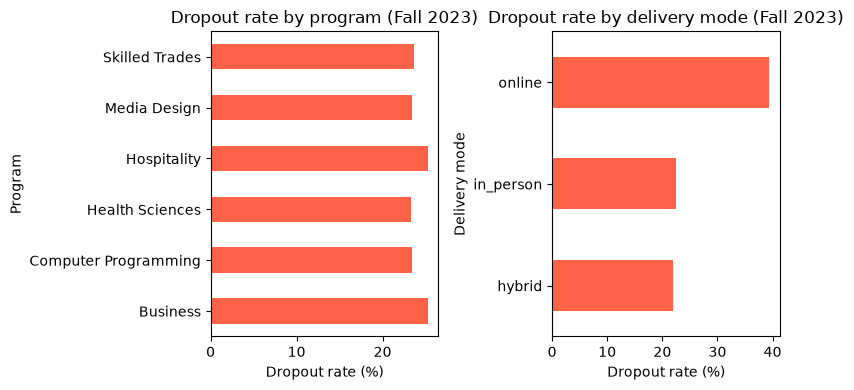

In [13]:
program_pct = df23.groupby("program")["did_not_return"].apply(
    lambda values: values.value_counts(normalize=True).get(1, 0) * 100
)

delivery_pct = df23.groupby("delivery_mode")["did_not_return"].apply(
    lambda values: values.value_counts(normalize=True).get(1, 0) * 100
)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

program_pct.plot(kind="barh", ax=axes[0], color="tomato")
axes[0].set_title("Dropout rate by program (Fall 2023)")
axes[0].set_xlabel("Dropout rate (%)")
axes[0].set_ylabel("Program")

delivery_pct.plot(kind="barh", ax=axes[1], color="tomato")
axes[1].set_title("Dropout rate by delivery mode (Fall 2023)")
axes[1].set_xlabel("Dropout rate (%)")
axes[1].set_ylabel("Delivery mode")

plt.tight_layout()
plt.show()

### Model Training and Holdout Validation (25%)


#### Feature engineering and preprocessing

In [14]:
#  Drop identifiers and target 
def prepare_features(df):
    features = df.drop(
        columns=["student_id", "intake_term", "did_not_return"]
    ).copy()
    # new feature for has any outstanding balance 
    features["has_balance"] = (features["outstanding_balance"] > 0).astype(int)
    return features


X23 = prepare_features(df23)
y23 = df23['did_not_return'].copy()
bin_cols.append("has_balance")

#### Pipeline for Preprocessing

In [15]:
# Preprocessing: scale numeric, one-hot encode categorical
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('bin', 'passthrough', bin_cols),   
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ]
)

In [16]:
model = Pipeline(steps=[
    ('prep', preprocessor),
    ('clf', LogisticRegression(class_weight='balanced',
                               max_iter=1000,
                               random_state=42))
])

#### Split Data into Train / Test

Train/test split (25% held-out test set)

In [17]:
X23_train, X23_test, y23_train, y23_test = train_test_split(
    X23, y23,
    test_size=0.25,
    stratify=y23,
    random_state=42
)

print('Train size:', X23_train.shape)
print('Test size :', X23_test.shape)
print('Train dropout rate:', y23_train.mean().round(4))
print('Test dropout rate :', y23_test.mean().round(4))

Train size: (3150, 14)
Test size : (1050, 14)
Train dropout rate: 0.2406
Test dropout rate : 0.241


#### Train the model

In [18]:
# Fit the model on the training set
model.fit(X23_train, y23_train)
print('Model trained.')

Model trained.


In [19]:
# Sanity check: predicted risk distribution on the training set - class_weight='balanced'
train_proba = model.predict_proba(X23_train)[:, 1]
print('Train predicted risk: min=%.3f, mean=%.3f, max=%.3f'
      % (train_proba.min(), train_proba.mean(), train_proba.max()))

Train predicted risk: min=0.001, mean=0.424, max=0.995


### Baseline Performance at the 0.30 Alert Threshold


In [20]:
# Metrics at the 0.30 EarlyAlert threshold (Fall 2023 test set)
y23_test_proba = model.predict_proba(X23_test)[:, 1]
y23_test_pred  = (y23_test_proba >= 0.30).astype(int)

acc  = accuracy_score(y23_test, y23_test_pred)
auc  = roc_auc_score(y23_test, y23_test_proba)
rec  = recall_score(y23_test, y23_test_pred)        # TP / (TP + FN)
prec = precision_score(y23_test, y23_test_pred)     # TP / (TP + FP)
pct_flagged = y23_test_pred.mean() * 100
mean_risk   = y23_test_proba.mean()
actual_rate = y23_test.mean()

print(f'Accuracy        : {acc:.4f}')
print(f'AUC             : {auc:.4f}')
print(f'Recall          : {rec:.4f}')
print(f'Precision       : {prec:.4f}')
print(f'% flagged       : {pct_flagged:.2f}%')
print(f'Mean pred risk  : {mean_risk:.4f}')
print(f'Actual dropout  : {actual_rate:.4f}')

# Confusion matrix (positive = did_not_return)
cm = confusion_matrix(y23_test, y23_test_pred)
print('\nConfusion matrix [ [TN, FP], [FN, TP] ]:')
print(cm)
print('Dropouts never flagged (FN):', cm[1, 0])

Accuracy        : 0.5762
AUC             : 0.8029
Recall          : 0.8972
Precision       : 0.3514
% flagged       : 61.52%
Mean pred risk  : 0.4215
Actual dropout  : 0.2410

Confusion matrix [ [TN, FP], [FN, TP] ]:
[[378 419]
 [ 26 227]]
Dropouts never flagged (FN): 26


I went with logistic regression and used class_weight='balanced' because the whole point of EarlyAlert is to catch students at risk — so recall matters more than accuracy, and dropouts are a minority in the data anyway. LR also gives us proper probabilities, which is important since the threshold is fixed at 0.30, and the coefficients are easy to read when we have to explain the results in the report. I thought about random forest, but it's harder to calibrate and basically a black box when you need to justify why a student got flagged, so I didn't go with it for this audit.

## Out-of-Time Model Validation | Fall 2025
### Overall Performance Comparison


#### Apply the unchanged model to Fall 2025


In [21]:
# Same feature engineering as Part 1, but NO refitting ---
X25 = prepare_features(df25)
y25 = df25['did_not_return'].copy()

In [22]:
# Predict risk on the entire 2025 cohort (no train/test split here) 
y25_proba = model.predict_proba(X25)[:, 1]
y25_pred  = (y25_proba >= 0.30).astype(int)

In [23]:
# Same metrics as 1.3
acc25  = accuracy_score(y25, y25_pred)
auc25  = roc_auc_score(y25, y25_proba)
rec25  = recall_score(y25, y25_pred)                # TP / (TP + FN)
prec25 = precision_score(y25, y25_pred)             # TP / (TP + FP)
pct_flagged25 = y25_pred.mean() * 100
mean_risk25   = y25_proba.mean()
actual_rate25 = y25.mean()

print('=== Fall 2025 (deployed, unchanged model) ===')
print(f'Accuracy        : {acc25:.4f}')
print(f'AUC             : {auc25:.4f}')
print(f'Recall          : {rec25:.4f}')
print(f'Precision       : {prec25:.4f}')
print(f'% flagged       : {pct_flagged25:.2f}%')
print(f'Mean pred risk  : {mean_risk25:.4f}')
print(f'Actual dropout  : {actual_rate25:.4f}')

# Confusion matrix for cross-check
cm25 = confusion_matrix(y25, y25_pred)
print('\nConfusion matrix [ [TN, FP], [FN, TP] ]:')
print(cm25)

print('Dropouts never flagged (FN):', cm25[1, 0])

=== Fall 2025 (deployed, unchanged model) ===
Accuracy        : 0.7177
AUC             : 0.7536
Recall          : 0.5138
Precision       : 0.6386
% flagged       : 29.23%
Mean pred risk  : 0.2244
Actual dropout  : 0.3633

Confusion matrix [ [TN, FP], [FN, TP] ]:
[[2071  412]
 [ 689  728]]
Dropouts never flagged (FN): 689


#### Side-by-side comparison

In [24]:
# Side-by-side comparison for Table 1
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'AUC', 'Recall', 'Precision',
               '% flagged', 'Mean predicted risk', 'Actual dropout rate'],
    'Fall 2023 test': [acc, auc, rec, prec, pct_flagged, mean_risk, actual_rate],
    'Fall 2025 deployed': [acc25, auc25, rec25, prec25, pct_flagged25,
                           mean_risk25, actual_rate25]
})
comparison['Difference'] = comparison['Fall 2025 deployed'] - comparison['Fall 2023 test']
print(comparison.round(4).to_string(index=False))

             Metric  Fall 2023 test  Fall 2025 deployed  Difference
           Accuracy          0.5762              0.7177      0.1415
                AUC          0.8029              0.7536     -0.0493
             Recall          0.8972              0.5138     -0.3835
          Precision          0.3514              0.6386      0.2872
          % flagged         61.5238             29.2308    -32.2930
Mean predicted risk          0.4215              0.2244     -0.1971
Actual dropout rate          0.2410              0.3633      0.1224


### Subgroup Performance and Risk Disparities

I chose my subgroups based on what actually changed in the change log, so each group maps to a specific event:

* Delivery mode → Summer 2024 online expansion

* Age (under 25 vs 25+) → same event, marketed to working adults

* International → Jan 2024 study permit cap

* Balance owing → Fall 2025 deregistration policy

That way, if a group performs badly, I can point to a specific event instead of just saying "drift happened".

#### Subgroup analysis on Fall 2025

In [25]:
# 2.2 Subgroup analysis on Fall 2025

def subgroup_report(name, mask, y_true, y_proba, threshold=0.30):
    """Compute comprehensive subgroup metrics for one subgroup."""
    y_t = y_true[mask]
    p   = y_proba[mask]
    pred = (p >= threshold).astype(int)
    n = int(mask.sum())
    n_dropouts = int((y_t == 1).sum())
    n_missed   = int(((y_t == 1) & (pred == 0)).sum())
    return {
        'group': name,
        'n': n,
        'n_dropouts': n_dropouts,
        'n_missed': n_missed,
        'mean_predicted_risk': round(float(p.mean()), 4) if n else np.nan,
        'actual_dropout_rate': round(float(y_t.mean()), 4) if n else np.nan,
        'recall': round(float(recall_score(y_t, pred, zero_division=0)), 4) if n else np.nan,
    }

rows = []

# --- Group 1: delivery mode ---
for mode in ['in_person', 'hybrid', 'online']:
    mask = (df25['delivery_mode'] == mode).values
    rows.append(subgroup_report(f'delivery={mode}', mask, y25.values, y25_proba))

# --- Group 2: age ---
rows.append(subgroup_report('age < 25',
              (df25['age'] < 25).values, y25.values, y25_proba))
rows.append(subgroup_report('age >= 25',
              (df25['age'] >= 25).values, y25.values, y25_proba))

# --- Group 3: international ---
rows.append(subgroup_report('domestic',
              (df25['international'] == 0).values, y25.values, y25_proba))
rows.append(subgroup_report('international',
              (df25['international'] == 1).values, y25.values, y25_proba))

# --- Group 4: balance owing ---
rows.append(subgroup_report('no balance',
              (df25['outstanding_balance'] == 0).values, y25.values, y25_proba))
rows.append(subgroup_report('balance owing',
              (df25['outstanding_balance'] > 0).values, y25.values, y25_proba))

subgroup_df = pd.DataFrame(rows)
subgroup_df['calibration_gap'] = (subgroup_df['actual_dropout_rate']
                                  - subgroup_df['mean_predicted_risk']).round(4)

print(subgroup_df.to_string(index=False))

             group    n  n_dropouts  n_missed  mean_predicted_risk  actual_dropout_rate  recall  calibration_gap
delivery=in_person 1728         551       314               0.1847               0.3189  0.4301           0.1342
   delivery=hybrid  792         242       140               0.1698               0.3056  0.4215           0.1358
   delivery=online 1380         624       235               0.3055               0.4522  0.6234           0.1467
          age < 25 2711         916       513               0.1879               0.3379  0.4400           0.1500
         age >= 25 1189         501       176               0.3076               0.4214  0.6487           0.1138
          domestic 3324        1201       585               0.2243               0.3613  0.5129           0.1370
     international  576         216       104               0.2250               0.3750  0.5185           0.1500
        no balance 2808         781       337               0.2207               0.2781  0.5685 

 *Note: Each grouping dimension partitions the full Fall 2025 cohort (n = 3900) independently; a student appears in one row per dimension.*
 n          = mask.sum()  
n_dropouts = y[mask].sum()  
n_missed   = ((y[mask] == 1) & (p[mask] < 0.30)).sum()  
recall     = (n_dropouts - n_missed) / n_dropouts  
mean_risk  = p[mask].mean()  
actual     = n_dropouts / n  
gap        = actual - mean_risk  

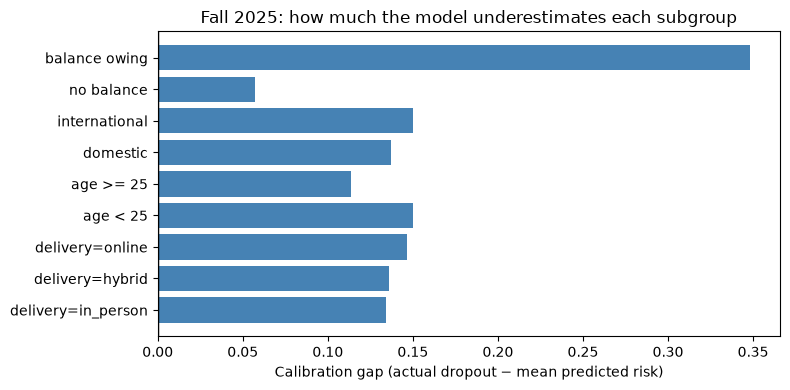

In [26]:
# calibration gap（actual − predicted risk）
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(subgroup_df['group'], subgroup_df['calibration_gap'], color="steelblue")
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('Calibration gap (actual dropout − mean predicted risk)')
ax.set_title('Fall 2025: how much the model underestimates each subgroup')
plt.tight_layout()
plt.show()

*Balance-owing students have the highest dropout rate (58.2%) but the lowest recall (44.7%) and largest calibration gap (0.35), pointing to the Fall 2025 deregistration policy as a major unlearned driver of dropout.*

The subgroup results point to one clear problem: students with an outstanding balance. Their actual dropout rate is 58.2%, more than double the no-balance group (27.8%), but the model gives them almost the same average risk score (0.234 vs 0.221) and actually catches fewer of them (recall 44.7% vs 56.9%). The calibration gap is 0.35, by far the worst of any group. This lines up with the Fall 2025 deregistration policy — the policy turned "owing money" into a direct trigger for leaving, but the model was trained before that and never learned it.

The other groups show a milder version of the same issue: every group's mean predicted risk is below its actual dropout rate, so the model is systematically under-flagging across the board. Online and 25+ students look better (recall 62–65%), but that's mostly because their risk scores are higher overall, not because the model understands them better. International students show almost no difference from domestic students, so the permit cap doesn't seem to be the main driver here.

Bottom line: the biggest harm is concentrated in the balance-owing group, and that's directly tied to the deregistration policy. That's the group the retrained model has to get right.

### False Negatives and Missed Dropouts



In [27]:
# Missed dropouts — corrected presentation

total_students = 3900
total_dropouts = 1417
total_missed    = 689
total_caught    = total_dropouts - total_missed

print('=== Overall ===')
print(f'Total students            : {total_students}')
print(f'Total dropouts            : {total_dropouts}')
print(f'Dropouts flagged          : {total_caught}')
print(f'Dropouts never flagged    : {total_missed}')
print(f'Overall recall            : {total_caught/total_dropouts:.2%}')
print(f'Missed rate among dropouts: {total_missed/total_dropouts:.2%}')

# Per-group metrics that actually reveal severity
groups = {
    'delivery': [
        ('in_person',     1728, 551, 314),
        ('hybrid',         792, 242, 140),
        ('online',        1380, 624, 235),
    ],
    'age': [
        ('<25',           2711, 916, 513),
        ('>=25',          1189, 501, 176),
    ],
    'international': [
        ('domestic',      3324, 1201, 585),
        ('international',  576,  216, 104),
    ],
    'balance': [
        ('no balance',    2808,  781, 337),
        ('balance owing', 1092,  636, 352),
    ],
}

print('\n=== Per-group severity (higher missed_rate_in_group / lower recall = worse) ===')
print(f'{"group":18s} {"n":>5s} {"n_drop":>7s} {"n_miss":>7s} '
      f'{"missed%_of_group":>18s} {"recall":>8s}')
for dim, rows in groups.items():
    print(f'-- {dim} --')
    for name, n, n_drop, n_miss in rows:
        missed_rate_group = n_miss / n
        recall = (n_drop - n_miss) / n_drop
        print(f'{name:18s} {n:5d} {n_drop:7d} {n_miss:7d} '
              f'{missed_rate_group:17.2%} {recall:8.2%}')

=== Overall ===
Total students            : 3900
Total dropouts            : 1417
Dropouts flagged          : 728
Dropouts never flagged    : 689
Overall recall            : 51.38%
Missed rate among dropouts: 48.62%

=== Per-group severity (higher missed_rate_in_group / lower recall = worse) ===
group                  n  n_drop  n_miss   missed%_of_group   recall
-- delivery --
in_person           1728     551     314            18.17%   43.01%
hybrid               792     242     140            17.68%   42.15%
online              1380     624     235            17.03%   62.34%
-- age --
<25                 2711     916     513            18.92%   44.00%
>=25                1189     501     176            14.80%   64.87%
-- international --
domestic            3324    1201     585            17.60%   51.29%
international        576     216     104            18.06%   51.85%
-- balance --
no balance          2808     781     337            12.00%   56.85%
balance owing       1092     63

In [28]:
# 2.3 “What changed” comparison — fill from 1.3 and 2.1 outputs
compare = pd.DataFrame({
    'Metric': ['Accuracy', 'AUC', 'Recall', '% flagged',
               'Mean predicted risk', 'Actual dropout rate', 'Dropouts never flagged'],
    'Fall 2023 (test)': [acc, auc, rec, pct_flagged,
                          mean_risk, actual_rate, cm[1, 0]],
    'Fall 2025 (all)': [acc25, auc25, 0.5138, pct_flagged25,
                         mean_risk25, 0.3633, 689],
})
print(compare.round(4))

                   Metric  Fall 2023 (test)  Fall 2025 (all)
0                Accuracy            0.5762           0.7177
1                     AUC            0.8029           0.7536
2                  Recall            0.8972           0.5138
3               % flagged           61.5238          29.2308
4     Mean predicted risk            0.4215           0.2244
5     Actual dropout rate            0.2410           0.3633
6  Dropouts never flagged           26.0000         689.0000


In [29]:
# Accuracy hides the problem
naive_baseline_acc = 1 - total_dropouts / total_students   
print(f'Naive "everyone stays" accuracy : {naive_baseline_acc:.2%}')
print(f'Model recall (dropouts caught)  : {total_caught/total_dropouts:.2%}')
print(f'Model missed rate               : {total_missed/total_dropouts:.2%}')

Naive "everyone stays" accuracy : 63.67%
Model recall (dropouts caught)  : 51.38%
Model missed rate               : 48.62%


Of the 1,417 Fall 2025 students who actually left, 689 (48.6%) were never flagged at the 0.30 threshold — 17.7% of the full cohort. The model catches roughly half of the dropouts.

What changed. On the 2023 test set, recall was 89.7% and 61.5% of students were flagged. On Fall 2025, recall dropped to 51.4% (−38.3pp) and only 29.2% were flagged (−32.3pp), while the actual dropout rate rose from 24.1% to 36.3% (+12.2pp). Fewer alerts, more students leaving — exactly what the VP described. The cause is the mean predicted risk falling from 0.4215 to 0.2244: scores are lower across the board, so many students who used to cross 0.30 no longer do. AUC only dropped from 0.8029 to 0.7536, so the model can still rank students reasonably well. The cutoff just no longer sits where it should. This is calibration drift, not a ranking failure.

Why accuracy hid it. Accuracy rose from 57.6% to 71.8% and precision from 35.1% to 63.9%. A dashboard showing only these two would have said the model improved. It didn't. With a 36.3% dropout rate, a model that predicts "everyone stays" already scores 63.7% accuracy, so 71.8% is only 8.1pp above doing nothing. In 2023 the model's 57.6% was actually below that same baseline (75.9%) because it flagged too many students. Accuracy went up only because it flagged fewer — not because it caught more dropouts. Accuracy is dominated by the majority class and cannot detect this failure. Recall on the minority class can.

Where the missed dropouts sit. Share of all missed dropouts is misleading — it mostly reflects group size (domestic students are 5.8× more numerous than international). Within-group missed rate and recall are the right comparison:

* Balance owing: 32.2% missed, 44.7% recall — far worse than any other group (no balance: 12.0% missed, 56.9% recall).

* Domestic vs international: basically the same (17.6% vs 18.1% missed; recall 51.3% vs 51.9%). The permit cap is not driving this.

* Online and 25+: missed less (17.0% and 14.8%; recall 62.3% and 64.9%). The model isn't failing on every new group — it fails specifically on the money dimension.

Conclusion: accuracy would have shown "57.6% → 71.8%, fine"; recall shows 689 students left without ever being flagged. The problem concentrates in the balance-owing group, which tracks the Fall 2025 deregistration policy the model was never retrained for.

## Data Drift Detection and Diagnostics
### Population Stability Index (PSI) by Feature



In [30]:
# add engineered features to the raw dataframes first
# (has_balance is engineered in 1.2 on X23/X25, but PSI runs on raw df23/df25)
df23['has_balance'] = (df23['outstanding_balance'] > 0).astype(int)
df25['has_balance'] = (df25['outstanding_balance'] > 0).astype(int)

# sanity check: every feature must exist in both raw dataframes
missing_23 = [f for f in (num_cols + bin_cols + cat_cols) if f not in df23.columns]
missing_25 = [f for f in (num_cols + bin_cols + cat_cols) if f not in df25.columns]
print('Missing in df23:', missing_23)
print('Missing in df25:', missing_25)

Missing in df23: []
Missing in df25: []


In [31]:
# PSI function (handles numeric, binary, and categorical features)

def psi_numeric(expected, actual, bins=10, eps=1e-6):
    """PSI using expected (2023) quantiles as bin edges."""
    # qcut with duplicates='drop' handles features with many repeated values (e.g. many zeros)
    _, bin_edges = pd.qcut(expected, q=bins, retbins=True, duplicates='drop')
    bin_edges = np.unique(np.concatenate([[-np.inf], bin_edges, [np.inf]])).astype(float)

    exp_bins = pd.cut(expected, bins=bin_edges, include_lowest=True)
    act_bins = pd.cut(actual,   bins=bin_edges, include_lowest=True)

    exp_pct = exp_bins.value_counts(normalize=True, sort=False)
    act_pct = act_bins.value_counts(normalize=True, sort=False)

    exp_pct, act_pct = exp_pct.align(act_pct, fill_value=eps)
    exp_pct = exp_pct.clip(lower=eps)
    act_pct = act_pct.clip(lower=eps)

    return float(((act_pct - exp_pct) * np.log(act_pct / exp_pct)).sum())


def psi_categorical(expected, actual, eps=1e-6):
    """PSI for binary or categorical features using category proportions."""
    exp_pct = expected.value_counts(normalize=True)
    act_pct = actual.value_counts(normalize=True)
    exp_pct, act_pct = exp_pct.align(act_pct, fill_value=0)
    exp_pct = exp_pct.clip(lower=eps)
    act_pct = act_pct.clip(lower=eps)
    return float(((act_pct - exp_pct) * np.log(act_pct / exp_pct)).sum())


# --- Compute PSI for every feature ---
all_features = num_cols + bin_cols + cat_cols

psi_rows = []
for feat in all_features:
    if feat in num_cols:
        psi = psi_numeric(df23[feat], df25[feat], bins=10)
    else:
        psi = psi_categorical(df23[feat], df25[feat])

    if psi < 0.10:
        color = 'GREEN'
    elif psi < 0.25:
        color = 'AMBER'
    else:
        color = 'RED'

    psi_rows.append({'feature': feat, 'PSI': round(psi, 4), 'colour': color})

psi_df = pd.DataFrame(psi_rows).sort_values('PSI', ascending=False)
print(psi_df.to_string(index=False))

                  feature    PSI colour
     lms_logins_first4wks 3.4637    RED
            delivery_mode 0.4468    RED
          commute_minutes 0.4099    RED
            international 0.1575  AMBER
                      age 0.1427  AMBER
          work_hours_week 0.0228  GREEN
assignments_submitted_pct 0.0150  GREEN
               hs_average 0.0073  GREEN
      outstanding_balance 0.0044  GREEN
                  program 0.0042  GREEN
        credits_attempted 0.0011  GREEN
              has_balance 0.0010  GREEN
         first_generation 0.0001  GREEN
            financial_aid 0.0001  GREEN


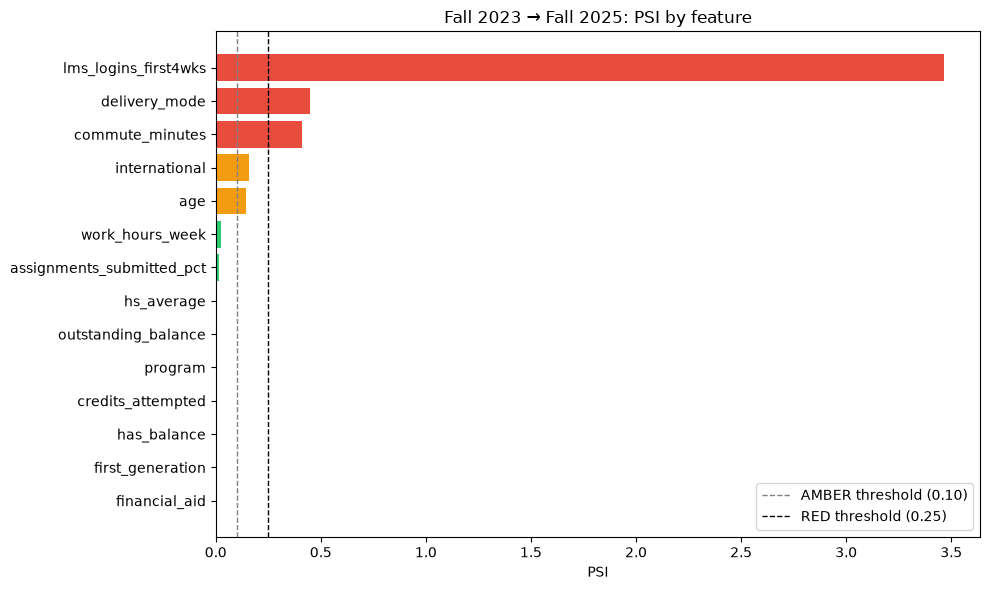

In [32]:
# Chart 1: PSI bar chart, coloured by category
fig, ax = plt.subplots(figsize=(10, 6))
colour_map = {'GREEN': '#2ecc71', 'AMBER': '#f39c12', 'RED': '#e74c3c'}
colors = [colour_map[c] for c in psi_df['colour']]
ax.barh(psi_df['feature'], psi_df['PSI'], color=colors)
ax.axvline(0.10, color='gray', linestyle='--', linewidth=1, label='AMBER threshold (0.10)')
ax.axvline(0.25, color='black', linestyle='--', linewidth=1, label='RED threshold (0.25)')
ax.set_xlabel('PSI')
ax.set_title('Fall 2023 → Fall 2025: PSI by feature')
ax.legend()
ax.invert_yaxis()
plt.tight_layout()
plt.show()

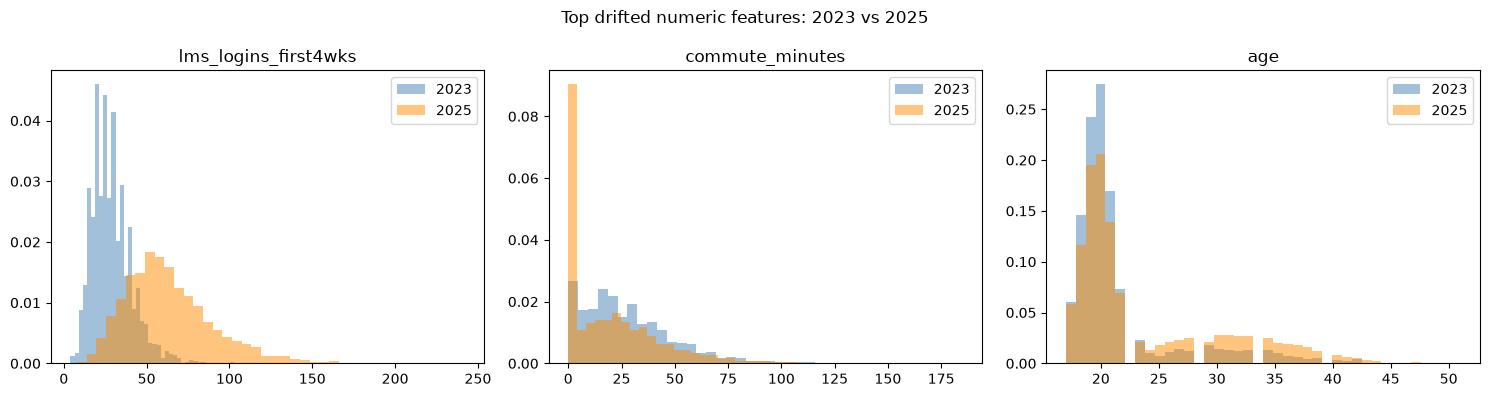

In [33]:
# Chart 2: Overlaid histograms for the top-drifted numeric features
top_numeric = psi_df[psi_df['feature'].isin(num_cols)].head(3)['feature'].tolist()

fig, axes = plt.subplots(1, len(top_numeric), figsize=(15, 4))
if len(top_numeric) == 1:
    axes = [axes]
for ax, feat in zip(axes, top_numeric):
    ax.hist(df23[feat], bins=40, alpha=0.5, label='2023', density=True, color='steelblue')
    ax.hist(df25[feat], bins=40, alpha=0.5, label='2025', density=True, color='darkorange')
    ax.set_title(feat)
    ax.legend()
plt.suptitle('Top drifted numeric features: 2023 vs 2025')
plt.tight_layout()
plt.show()

Overall. 14 features: 3 RED (≥0.25), 2 AMBER (0.10–0.25), 9 GREEN (<0.10). PSI was computed with 10 quantile bins from Fall 2023 as the reference, so each PSI value measures how far the 2025 distribution has moved relative to 2023.

Three RED.

lms_logins_first4wks PSI = 3.46. This isn't drift, it's a different feature. The threshold is 0.25 and it's 14× over. Matches the Jan 2025 LMS migration: the new vendor tracks logins differently, so the whole distribution shifted right.

delivery_mode PSI = 0.45. Matches the Summer 2024 online expansion — the 2025 cohort has a much larger online share.

commute_minutes PSI = 0.41. No event in the change log explains this directly. Most likely a side effect of the online expansion (online students report 0 commute minutes, so the distribution shifts left as their share grows), but that should be verified with 3.2 and 3.3 rather than assumed.

Two AMBER.

international PSI = 0.16. Matches the Jan 2024 study permit cap.

age PSI = 0.14. Matches the Summer 2024 marketing to working adults.

Both are mild. Not every change-log event caused a serious shift — some just nudged the distribution, and the model held up on those dimensions (The out-of-time evaluation shows international recall ≈ domestic, age 25+ recall actually higher).

The GREEN that matters: outstanding_balance PSI = 0.0044. From PSI alone, the balance distribution barely moved. But Part 2 already showed the balance-owing group has the lowest recall (44.7%) and the largest calibration gap (0.35) of any subgroup. PSI says "no problem", Part 2 says "worst group" — these aren't contradictory, but they do mean PSI alone can't tell the whole story. has_balance PSI = 0.0010 also rules out "more students owe money" as the explanation, so whatever is going on with that group isn't a distribution shift at all.

Other GREEN features: work_hours_week (0.023), assignments_submitted_pct (0.015), hs_average (0.007), program (0.004), credits_attempted (0.001), first_generation (0.0001), financial_aid (0.0001). These are stable between cohorts and can be ruled out as drift sources.

### Statistical Distribution Tests (KS, Wasserstein, Chi-Square)


In [34]:
from scipy.stats import ks_2samp, wasserstein_distance, chi2_contingency

second_rows = []
for feat in all_features:
    if feat in num_cols:
        ks_stat, ks_p = ks_2samp(df23[feat], df25[feat])
        w_dist = wasserstein_distance(df23[feat], df25[feat])
        second_rows.append({
            'feature': feat,
            'test': 'KS + Wasserstein',
            'KS_stat': round(ks_stat, 4),
            'KS_p': float(f'{ks_p:.2e}'),
            'Wasserstein': round(w_dist, 4)
        })
    else:
        # FIXED: ignore_index=True to avoid duplicate labels in crosstab
        combined_vals = pd.concat(
            [df23[feat], df25[feat]], ignore_index=True
        )
        combined_cohort = pd.concat(
            [pd.Series(['2023'] * len(df23)),
             pd.Series(['2025'] * len(df25))],
            ignore_index=True
        )
        ct = pd.crosstab(combined_vals, combined_cohort)
        chi2, chi_p, dof, _ = chi2_contingency(ct)
        second_rows.append({
            'feature': feat,
            'test': 'chi-square',
            'KS_stat': round(chi2, 4),
            'KS_p': float(f'{chi_p:.2e}'),
            'Wasserstein': np.nan
        })

second_df = pd.DataFrame(second_rows)
print(second_df.to_string(index=False))

comparison = psi_df.merge(second_df, on='feature', how='left')
print('\n=== PSI vs second test ===')
print(comparison.to_string(index=False))

                  feature             test  KS_stat          KS_p  Wasserstein
                      age KS + Wasserstein   0.1561  1.790000e-43       2.0403
               hs_average KS + Wasserstein   0.0256  1.380000e-01       0.2596
        credits_attempted KS + Wasserstein   0.0128  8.900000e-01       0.0505
          work_hours_week KS + Wasserstein   0.0551  8.800000e-06       1.3858
          commute_minutes KS + Wasserstein   0.2541 3.600000e-115       7.8107
     lms_logins_first4wks KS + Wasserstein   0.6689  0.000000e+00      34.6237
assignments_submitted_pct KS + Wasserstein   0.0444  6.640000e-04       1.3708
      outstanding_balance KS + Wasserstein   0.0140  8.130000e-01      18.4978
            international       chi-square 303.5901  5.440000e-68          NaN
         first_generation       chi-square   0.1621  6.870000e-01          NaN
            financial_aid       chi-square   0.1930  6.600000e-01          NaN
              has_balance       chi-square   1.9418 

What I ran. KS test + Wasserstein distance for numeric features, chi-square for categorical/binary, compared against PSI.

They agree on most things. All three RED features are confirmed: lms_logins_first4wks (KS D=0.669, W=34.6 logins), delivery_mode (χ²=834, p<0.001), commute_minutes (KS D=0.254, W=7.8 min). Same for the two AMBER features: age (KS D=0.156, W=2.04 years) and international (χ²=304, p<0.001). So PSI isn't exaggerating anything here.

Where they disagree, there are three cases.

work_hours_week and assignments_submitted_pct have KS p-values < 0.001 but PSI GREEN. Not a real conflict — KS's p-value scales with sample size, and with 4,200 vs 3,900 students even a tiny difference looks "significant". The effect sizes say it better: KS D = 0.055 / 0.044, Wasserstein = 1.4 hours / 1.4 pp. That's noise. GREEN is the right label; the p-value is just being dramatic.

outstanding_balance is the interesting one. PSI = 0.0044, KS D = 0.014 (p=0.813), so both say "no drift". But Wasserstein = 18.5, which is huge. The reason is that PSI and KS look at the bulk of the distribution, while Wasserstein measures the area between the two CDFs and therefore cares about the tail. A handful of 2025 students owe $3,000–$5,000, which drags the tail out and inflates Wasserstein even though the bulk didn't move. So the 18.5 is real but it's a tail signal, not a bulk shift.

Cross-checking with Part 2: has_balance PSI = 0.001 and χ² p = 0.163, so the proportion of students owing money didn't change either. Yet the balance-owing group has the lowest recall (44.7%) and the biggest calibration gap (0.35) of any subgroup. Put it together and the conclusion is that the balance distribution is stable, but what "owing money" means for dropout changed — the Fall 2025 deregistration policy turned it from a mild risk factor into a direct trigger. That's a concept drift, not a data drift. PSI and KS can't see it by design, because they only look at the feature, not at how the feature relates to the outcome.

Why this matters. The RED and AMBER calls from PSI are trustworthy — the second test confirms them. The disagreements are informative rather than contradictory: two are p-value inflation from a big sample, and one is a tail-only shift that only Wasserstein picks up. None of the tests can catch concept drift. That's what the subgroup analysis in the out-of-time evaluation is for.

### Model-Based Drift Detection: Domain Classifier

In [35]:
# Domain classifier: Fall 2023 = 0, Fall 2025 = 1

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# --- Combine the two cohorts (X23 / X25 must already have has_balance from Part 1/2) ---
df23_dom = X23.copy()
df23_dom['domain'] = 0

df25_dom = X25.copy()
df25_dom['domain'] = 1

df_domain = pd.concat([df23_dom, df25_dom], ignore_index=True)

X_dom = df_domain.drop(columns=['domain'])
y_dom = df_domain['domain']

print('Combined shape:', df_domain.shape)
print('Domain counts:', y_dom.value_counts().to_dict())

# --- Split 75/25, stratified by domain ---
X_dom_train, X_dom_test, y_dom_train, y_dom_test = train_test_split(
    X_dom, y_dom, test_size=0.25, stratify=y_dom, random_state=42
)

# --- Fit a fresh preprocessor on the domain data (different target from 1.2) ---
domain_model = Pipeline(steps=[
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])
domain_model.fit(X_dom_train, y_dom_train)

# --- Report AUC on the TEST set ---
y_dom_proba = domain_model.predict_proba(X_dom_test)[:, 1]
domain_auc = roc_auc_score(y_dom_test, y_dom_proba)
print(f'\nDomain classifier AUC (test set): {domain_auc:.4f}')

if domain_auc < 0.60:
    interp = 'little or no drift'
elif domain_auc < 0.70:
    interp = 'noticeable drift'
elif domain_auc < 0.80:
    interp = 'substantial drift'
else:
    interp = 'strong drift'
print(f'Interpretation: {interp}')

Combined shape: (8100, 15)
Domain counts: {0: 4200, 1: 3900}

Domain classifier AUC (test set): 0.9709
Interpretation: strong drift


In [36]:
# Get feature names after preprocessing
cat_encoder = domain_model.named_steps['prep'].named_transformers_['cat']
cat_feature_names = list(cat_encoder.get_feature_names_out(cat_cols))
feature_names = num_cols + bin_cols + cat_feature_names

coefs = domain_model.named_steps['clf'].coef_[0]

coef_df = pd.DataFrame({
    'feature': feature_names,
    'coef': coefs,
    'abs_coef': np.abs(coefs)
}).sort_values('abs_coef', ascending=False).reset_index(drop=True)

print('Top 10 features driving the domain classifier:')
print(coef_df.head(10).to_string(index=False))

Top 10 features driving the domain classifier:
                  feature      coef  abs_coef
     lms_logins_first4wks  5.293637  5.293637
assignments_submitted_pct -1.965993  1.965993
     delivery_mode_online  1.170897  1.170897
            international -1.069742  1.069742
  delivery_mode_in_person -0.596908  0.596908
     program_Media Design -0.252851  0.252851
                      age  0.187090  0.187090
      outstanding_balance  0.148168  0.148168
              has_balance  0.090893  0.090893
         first_generation  0.066061  0.066061


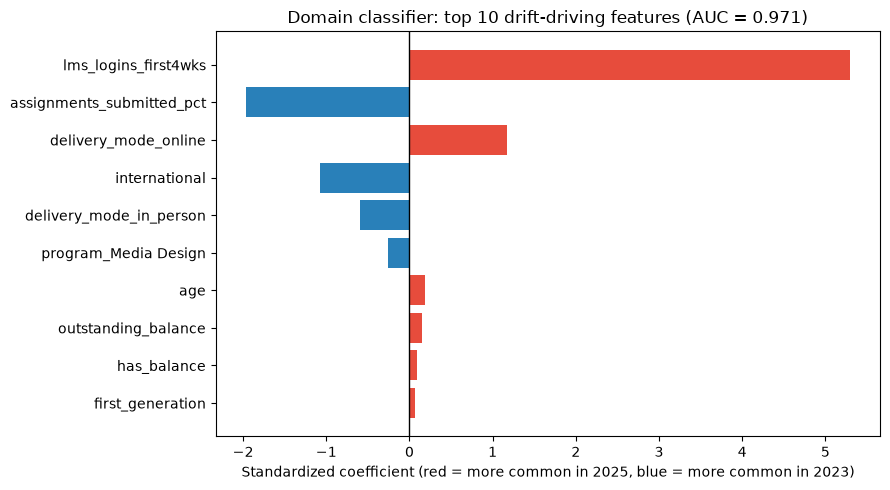

In [37]:
# Chart 3: domain classifier top features
top_k = 10
top = coef_df.head(top_k).iloc[::-1]  # reverse so biggest is on top

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#e74c3c' if c > 0 else '#2980b9' for c in top['coef']]
ax.barh(top['feature'], top['coef'], color=colors)
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('Standardized coefficient (red = more common in 2025, blue = more common in 2023)')
ax.set_title(f'Domain classifier: top {top_k} drift-driving features (AUC = {domain_auc:.3f})')
plt.tight_layout()
plt.show()

In [38]:
# Cross-check: do the PSI RED features show up in the domain classifier?
psi_red_amber = psi_df[psi_df['colour'].isin(['RED', 'AMBER'])]['feature'].tolist()
top10_features = coef_df.head(10)['feature'].tolist()

print('PSI RED/AMBER features:', psi_red_amber)
print('\nPresent in domain classifier top 10:')
for f in psi_red_amber:
    present = any(f in t for t in top10_features)
    print(f'  {f:30s} -> {"YES" if present else "NO"}')

# Specifically check outstanding_balance / has_balance
for f in ['outstanding_balance', 'has_balance']:
    rank = coef_df[coef_df['feature'] == f].index[0] + 1
    print(f'\n{f} ranked #{rank} out of {len(coef_df)} features')

PSI RED/AMBER features: ['lms_logins_first4wks', 'delivery_mode', 'commute_minutes', 'international', 'age']

Present in domain classifier top 10:
  lms_logins_first4wks           -> YES
  delivery_mode                  -> YES
  commute_minutes                -> NO
  international                  -> YES
  age                            -> YES

outstanding_balance ranked #8 out of 19 features

has_balance ranked #9 out of 19 features


In [39]:
print(coef_df.head(10)[['feature', 'coef', 'abs_coef']].to_string(index=False))

                  feature      coef  abs_coef
     lms_logins_first4wks  5.293637  5.293637
assignments_submitted_pct -1.965993  1.965993
     delivery_mode_online  1.170897  1.170897
            international -1.069742  1.069742
  delivery_mode_in_person -0.596908  0.596908
     program_Media Design -0.252851  0.252851
                      age  0.187090  0.187090
      outstanding_balance  0.148168  0.148168
              has_balance  0.090893  0.090893
         first_generation  0.066061  0.066061


Domain classifier results. AUC on the held-out test set = 0.9709, which falls in the strong drift range (> 0.80) under the chosen drift interpretation thresholds. The two cohorts are almost perfectly separable.

Top drivers (|standardized coefficient|): lms_logins_first4wks (5.29), assignments_submitted_pct (1.97), delivery_mode_online (1.17), international (1.07), delivery_mode_in_person (0.60). The same features that PSI flagged as RED/AMBER dominate the domain classifier — three independent methods (PSI, KS/Wasserstein, domain classifier) point to the same drift drivers.

Why 0.97 is high but not surprising. The single largest contributor is lms_logins_first4wks (|coef| = 5.29, ~2.7× the next feature). Its KS statistic (D = 0.669) means the 2023 and 2025 distributions barely overlap — consistent with the Jan 2025 LMS migration changing the tracking scale. Most other features barely moved (hs_average PSI 0.007, credits_attempted 0.001, financial_aid 0.0001), so the 0.97 is driven mainly by one re-scaled feature plus the online expansion, not by a wholesale change in the student population.

Where the domain classifier adds information PSI cannot.

First, commute_minutes has PSI = 0.41 (RED) but does not appear in the top 10. It is largely redundant with delivery_mode: online students report 0 commute minutes, so the online expansion mechanically shifts commute_minutes left. Once delivery_mode is in the model, commute_minutes adds little independent signal. PSI flags correlated features separately; the domain classifier discounts them automatically.

Second, assignments_submitted_pct has PSI GREEN (0.015) but ranks #2 (coef = −1.97). The negative coefficient means lower submission rates are more common in 2025, consistent with the overall drop in engagement. Marginal distribution stability does not imply joint irrelevance.

Where the domain classifier confirms the concept-drift story. outstanding_balance and has_balance rank #8 and #9 out of 19, but their coefficient magnitudes are 2.8% and 1.7% of the top driver, respectively. In other words, the ranking is mid-pack only because the remaining 11 features are smaller still; their actual contribution to domain separation is negligible. This is the third independent confirmation (after PSI and KS/chi-square) that the balance distribution did not shift. The balance-owing subgroup's poor performance (recall 44.7%, calibration gap 0.35 from the drift diagnostics) is therefore a concept drift — the feature didn't move, but what it means for dropout changed after the Fall 2025 deregistration policy.